In [1]:
import torch
import torch.nn as nn
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
import os

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [3]:
test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [4]:
model = models.efficientnet_b0(weights=None)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    11
)

model = model.to(device)

In [7]:
MODEL_PATH = "efficientnet_b0_best.pth"

In [8]:
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device)
)

model.eval()

print("✅ Model Loaded Successfully!")

✅ Model Loaded Successfully!


In [9]:
class_names = {
    0: "Live",
    1: "Printed Photo",
    2: "Replay Attack",
    3: "Cut Photo",
    4: "Warped Photo",
    5: "Mask Attack",
    6: "Screen Replay",
    7: "Partial Attack",
    8: "Obstruction",
    9: "Makeup Attack",
    10: "Other Spoof"
}

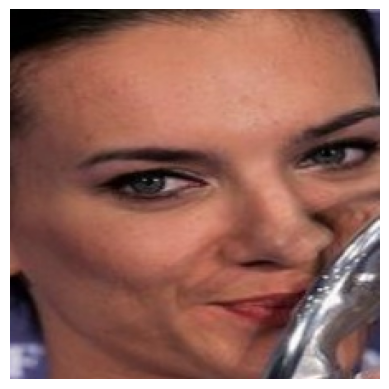

In [10]:
IMAGE_PATH = "test_face.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.show()

In [11]:
input_tensor = test_transform(image)

input_tensor = input_tensor.unsqueeze(0)

input_tensor = input_tensor.to(device)

In [12]:
import torch.nn.functional as F

with torch.no_grad():

    outputs = model(input_tensor)

    probabilities = F.softmax(outputs, dim=1)

    confidence, predicted = torch.max(probabilities, 1)

predicted_class = predicted.item()

confidence_score = confidence.item() * 100

print("Predicted Class :", predicted_class)
print("Confidence      : {:.2f}%".format(confidence_score))

Predicted Class : 0
Confidence      : 100.00%


In [13]:
print("=" * 50)
print("Prediction :", class_names[predicted_class])
print("Confidence : {:.2f}%".format(confidence_score))
print("=" * 50)

Prediction : Live
Confidence : 100.00%


In [14]:
import pandas as pd

df = pd.read_csv("train_dataframe.csv")

print(df["spoof_type"].value_counts().sort_index())

spoof_type
0     162462
1      35547
2      31221
3      31776
4      33647
5      30167
6      33285
7      31072
8      33085
9      31527
10     40616
Name: count, dtype: int64


In [15]:
print(df[["spoof_type"]].drop_duplicates().sort_values("spoof_type"))

    spoof_type
0            0
39           1
16           2
10           3
22           4
3            5
1            6
2            7
11           8
7            9
13          10


In [16]:
print(df.columns)

Index(['image_path', 'spoof_type', 'illumination', 'environment',
       'live_spoof'],
      dtype='str')


In [19]:
IMAGE_PATH = "spoog_test.jpg"

In [31]:
import pandas as pd

df = pd.read_csv("train_dataframe.csv")

print(df.columns)

print(df.head(10))

Index(['image_path', 'spoof_type', 'illumination', 'environment',
       'live_spoof'],
      dtype='str')
                         image_path  spoof_type  illumination  environment  \
0   Data/train/2623/live/000000.jpg           0             0            0   
1  Data/train/5489/spoof/000001.jpg           6             1            1   
2  Data/train/7149/spoof/000002.jpg           7             1            1   
3  Data/train/4980/spoof/000003.jpg           5             1            2   
4  Data/train/7124/spoof/000004.jpg           7             4            2   
5   Data/train/7013/live/000005.jpg           0             0            0   
6   Data/train/1857/live/000006.jpg           0             0            0   
7  Data/train/8206/spoof/000007.jpg           9             2            1   
8  Data/train/6980/spoof/000008.jpg           7             1            2   
9   Data/train/5319/live/000009.jpg           0             0            0   

   live_spoof  
0           0  
1 

In [32]:
print(df[df["spoof_type"] == 0].head(10))

                          image_path  spoof_type  illumination  environment  \
0    Data/train/2623/live/000000.jpg           0             0            0   
5    Data/train/7013/live/000005.jpg           0             0            0   
6    Data/train/1857/live/000006.jpg           0             0            0   
9    Data/train/5319/live/000009.jpg           0             0            0   
12   Data/train/5817/live/000012.jpg           0             0            0   
14    Data/train/354/live/000014.jpg           0             0            0   
17   Data/train/7657/live/000017.jpg           0             0            0   
19  Data/train/10044/live/000019.jpg           0             0            0   
32   Data/train/7476/live/000032.jpg           0             0            0   
36   Data/train/8687/live/000036.jpg           0             0            0   

    live_spoof  
0            0  
5            0  
6            0  
9            0  
12           0  
14           0  
17         

In [33]:
print(df[df["spoof_type"] == 8].head(10))

                          image_path  spoof_type  illumination  environment  \
11  Data/train/8032/spoof/000011.jpg           8             1            2   
15  Data/train/8134/spoof/000015.jpg           8             4            2   
26  Data/train/7897/spoof/000026.jpg           8             4            1   
46  Data/train/8014/spoof/000046.jpg           8             1            2   
51  Data/train/7904/spoof/000051.jpg           8             4            1   
73  Data/train/8111/spoof/000073.jpg           8             3            2   
86  Data/train/7539/spoof/000086.jpg           8             1            1   
89  Data/train/7647/spoof/000089.jpg           8             2            1   
93  Data/train/8112/spoof/000093.jpg           8             3            2   
97  Data/train/7870/spoof/000097.jpg           8             4            1   

    live_spoof  
11           1  
15           1  
26           1  
46           1  
51           1  
73           1  
86         

                              image_path  spoof_type  illumination  \
353352  Data/train/8612/spoof/353352.jpg           9             2   

        environment  live_spoof  
353352            1           1  
CelebA_Spoof_/CelebA_Spoof/Data/train/8612/spoof/353352.jpg


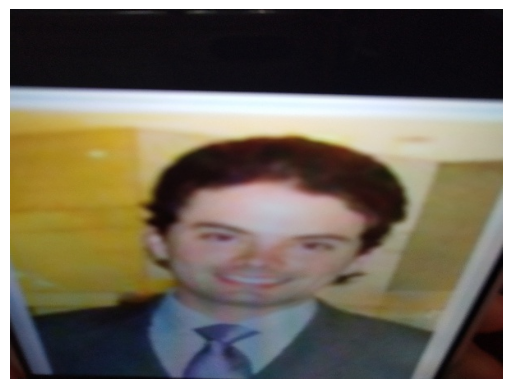

In [34]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

df = pd.read_csv("train_dataframe.csv")

# Select one spoof image
spoof_df = df[df["live_spoof"] == 1]

sample = spoof_df.sample(1, random_state=42)

print(sample)

image_path = sample.iloc[0]["image_path"]

full_path = "CelebA_Spoof_/CelebA_Spoof/" + image_path

print(full_path)

image = Image.open(full_path).convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.show()

In [35]:
IMAGE_PATH = "CelebA_Spoof_/CelebA_Spoof/Data/train/8612/spoof/353352.jpg"

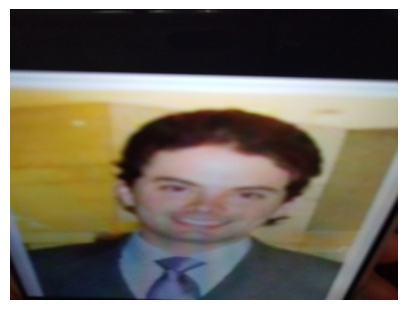

Ground Truth Spoof Type : 9
Predicted Spoof Type    : 9
Confidence              : 100.00%


In [36]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

image = Image.open(IMAGE_PATH).convert("RGB")

plt.figure(figsize=(5,5))
plt.imshow(image)
plt.axis("off")
plt.show()

input_tensor = test_transform(image)
input_tensor = input_tensor.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)

    probabilities = F.softmax(outputs, dim=1)

confidence, predicted = torch.max(probabilities, 1)

print("="*50)
print("Ground Truth Spoof Type :", 9)
print("Predicted Spoof Type    :", predicted.item())
print("Confidence              : {:.2f}%".format(confidence.item()*100))
print("="*50)

In [37]:
print("Ground Truth Spoof Type :", 9)

Ground Truth Spoof Type : 9


In [38]:
ground_truth = sample.iloc[0]["spoof_type"]

print("Ground Truth Spoof Type :", ground_truth)
print("Predicted Spoof Type    :", predicted.item())

if ground_truth == predicted.item():
    print("✅ Prediction Correct")
else:
    print("❌ Prediction Incorrect")

print(f"Confidence : {confidence.item()*100:.2f}%")

Ground Truth Spoof Type : 9
Predicted Spoof Type    : 9
✅ Prediction Correct
Confidence : 100.00%
